In [20]:
#Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.tree import plot_tree
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn import svm
from sklearn.svm import SVC
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
import numpy as np
#use pandas to read the dataframe, which is an excel file
hp = pd.read_excel("HousePricePrediction.xlsx")

In [21]:
#Taking a look at the first 5 rows of the dataframe to get an idea of what it looks like
hp.head()

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0,208500.0
1,1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0,181500.0
2,2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0,223500.0
3,3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0,140000.0
4,4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0,250000.0


In [22]:
hp.info()

<class 'pandas.DataFrame'>
RangeIndex: 2919 entries, 0 to 2918
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Id            2919 non-null   int64  
 1   MSSubClass    2919 non-null   int64  
 2   MSZoning      2915 non-null   str    
 3   LotArea       2919 non-null   int64  
 4   LotConfig     2919 non-null   str    
 5   BldgType      2919 non-null   str    
 6   OverallCond   2919 non-null   int64  
 7   YearBuilt     2919 non-null   int64  
 8   YearRemodAdd  2919 non-null   int64  
 9   Exterior1st   2918 non-null   str    
 10  BsmtFinSF2    2918 non-null   float64
 11  TotalBsmtSF   2918 non-null   float64
 12  SalePrice     1460 non-null   float64
dtypes: float64(3), int64(6), str(4)
memory usage: 296.6 KB


In [23]:
#Looking at its dimensions
hp.shape

(2919, 13)

The dataframe has 2919 entires, and 13 columns

In [24]:
#Categorizing features based on data types

#categorizing string variables
str_cols = hp.select_dtypes(include=['str']).columns
print("Categorical variables:", len(str_cols))

#Categorizing Integer variables
int_cols = hp.select_dtypes(include=['int64']).columns
print("Integer Variables:", len(int_cols))

#Categorizing Float variables
float_cols = hp.select_dtypes(include=['float64']).columns
print("Float Variables:", len(float_cols))

Categorical variables: 4
Integer Variables: 6
Float Variables: 3


Moving on to Exploratory Data Analysis

Heatmap saved as correlation_heatmap.png


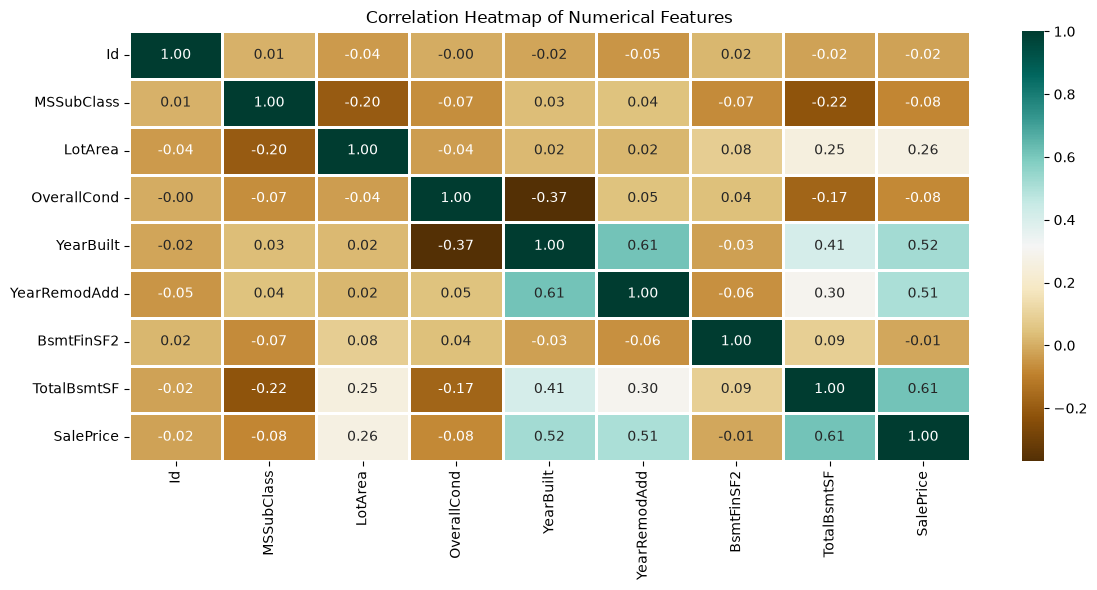

In [25]:
#Creating a heatmap using the seaborn library

#Selecting the datatypes in the dataframe that are integers and floats
num_hp = hp.select_dtypes(include=['int64', 'float64'])

#Configuring the size of the heatmap
plt.figure(figsize=(12, 6))

#Configuring it's specifications like the color mapping, the formatting, the width of the lines, and whether the data values will be within the cells or not
sns.heatmap(num_hp.corr(),
            cmap='BrBG', #the color mapping will be brown and blue-green
            fmt='.2f', #we're deciding the format
            linewidths=2, #The width of the lines will be 2
            annot=True) #There will be annotation on the cells
plt.title("Correlation Heatmap of Numerical Features") #The title of the heatmap
plt.tight_layout() #The type of layout
plt.savefig("correlation_heatmap.png") #We do this to save the, in this case, heatmap
print("Heatmap saved as correlation_heatmap.png") #And now we print

<Axes: title={'center': 'No. Unique values of categorical features'}, xlabel='None'>

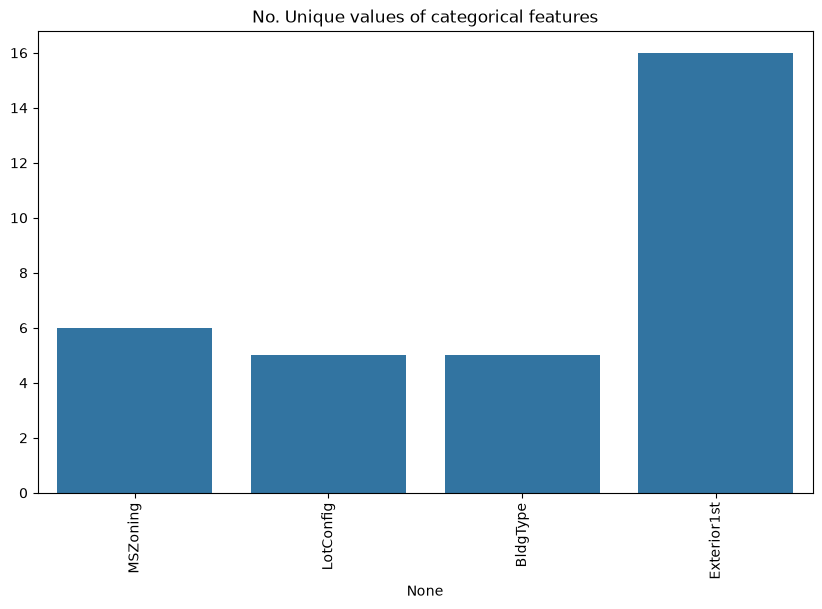

In [26]:
#Now to make a barplot to visualize the distributions between categorial features
unique_values = []
for col in str_cols: #Making a function
    unique_values.append(hp[col].unique().size)
plt.figure(figsize=(10,6))
plt.title("No. Unique values of categorical features")
plt.xticks(rotation=90)
sns.barplot(x=str_cols, y=unique_values)

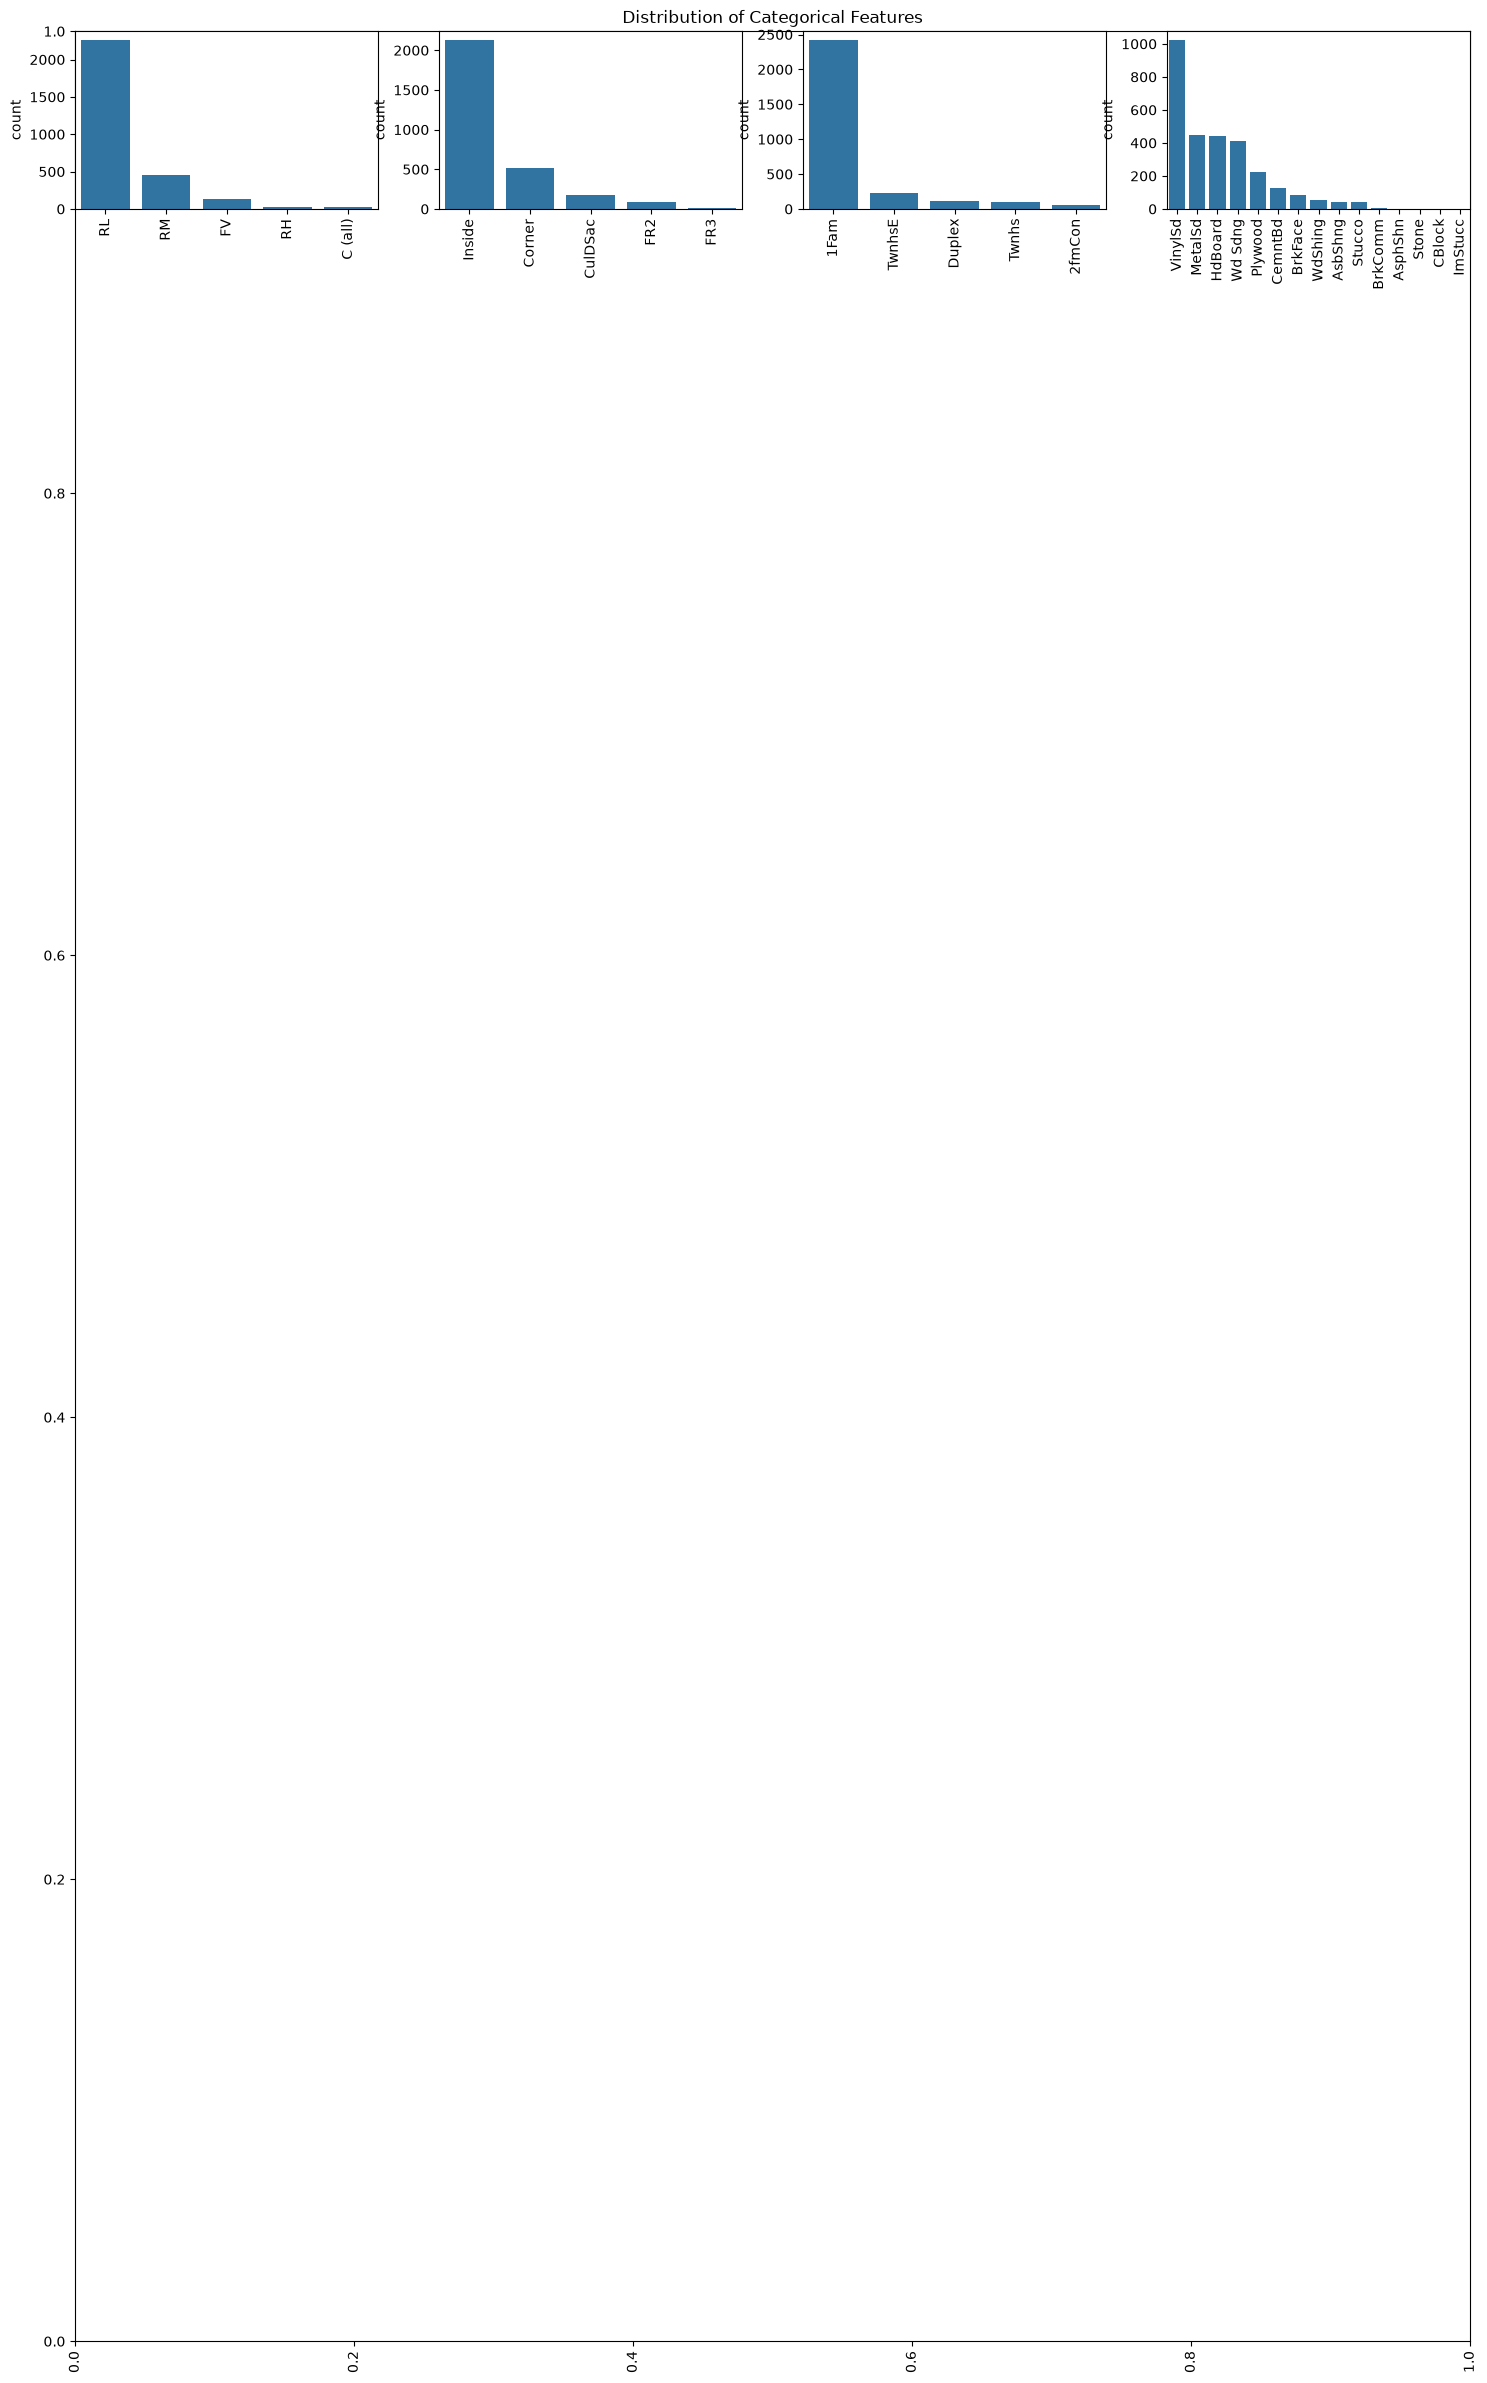

In [27]:
plt.figure(figsize=(18,30))
plt.title("Distribution of Categorical Features")
plt.xticks(rotation=90)

index = 1

for col in str_cols:
    y = hp[col].value_counts()
    plt.subplot(11, 4, index)
    plt.xticks(rotation=90)
    sns.barplot(x=list(y.index), y=y)
    index += 1
plt.savefig("cat_feat_distribution.png")

In [28]:
#As the id column isn't needed, we'll be getting rid of it
hp.drop(['Id'],
        axis=1)

,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0,208500.0
1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0,181500.0
2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0,223500.0
3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0,140000.0
4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0,250000.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2914,160,RM,1936,Inside,Twnhs,7,1970,1970,CemntBd,0.0,546.0,NaN
2915,160,RM,1894,Inside,TwnhsE,5,1970,1970,CemntBd,0.0,546.0,NaN
2916,20,RL,20000,Inside,1Fam,7,1960,1996,VinylSd,0.0,1224.0,NaN
2917,85,RL,10441,Inside,1Fam,5,1992,1992,HdBoard,0.0,912.0,NaN


In [29]:
hp['SalePrice'] = hp['SalePrice'].fillna(hp['SalePrice'].mean())

In [30]:
new_hp = hp.dropna()

In [31]:
new_hp.isnull().sum()

Id              0
MSSubClass      0
MSZoning        0
LotArea         0
LotConfig       0
BldgType        0
OverallCond     0
YearBuilt       0
YearRemodAdd    0
Exterior1st     0
BsmtFinSF2      0
TotalBsmtSF     0
SalePrice       0
dtype: int64

In [32]:
#Time to convert the categorial into binary vectors, mapping them into integer values via OneHotEncoder
from sklearn.preprocessing import OneHotEncoder

In [33]:
s = (new_hp.dtypes == 'str')
str_cols = list(s[s].index)
print("Cat. Variables:")
print(str_cols)
print("No. of. categorical features: ",
      len(str_cols))

Cat. Variables:
['MSZoning', 'LotConfig', 'BldgType', 'Exterior1st']
No. of. categorical features:  4


In [34]:
OH_encoding = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
OH_cols = pd.DataFrame(OH_encoding.fit_transform(new_hp[str_cols]))
OH_cols.index = new_hp.index
OH_cols.columns = OH_encoding.get_feature_names_out()
hp_final = new_hp.drop(str_cols, axis=1)
hp_final = pd.concat([hp_final, OH_cols], axis=1)

In [35]:

x = hp_final.drop(['SalePrice'], axis=1)
y = hp_final['SalePrice']

x_train, x_valid, y_train, y_valid = train_test_split(x, y, train_size=0.8, test_size=0.2, random_state=0)

In [36]:

model_SVR = svm.SVR()
model_SVR.fit(x_train,y_train)
y_pred = model_SVR.predict(x_valid)

print(mean_absolute_percentage_error(y_valid, y_pred))

0.18704778826125987


In [37]:

model_RFR = RandomForestRegressor(n_estimators=10)
model_RFR.fit(x_train, y_train)
y_pred = model_RFR.predict(x_valid)

mean_absolute_percentage_error(y_valid, y_pred)

0.08314059623145618

In [39]:
model_RFR

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numbe

<function matplotlib.pyplot.show(close=None, block=None)>

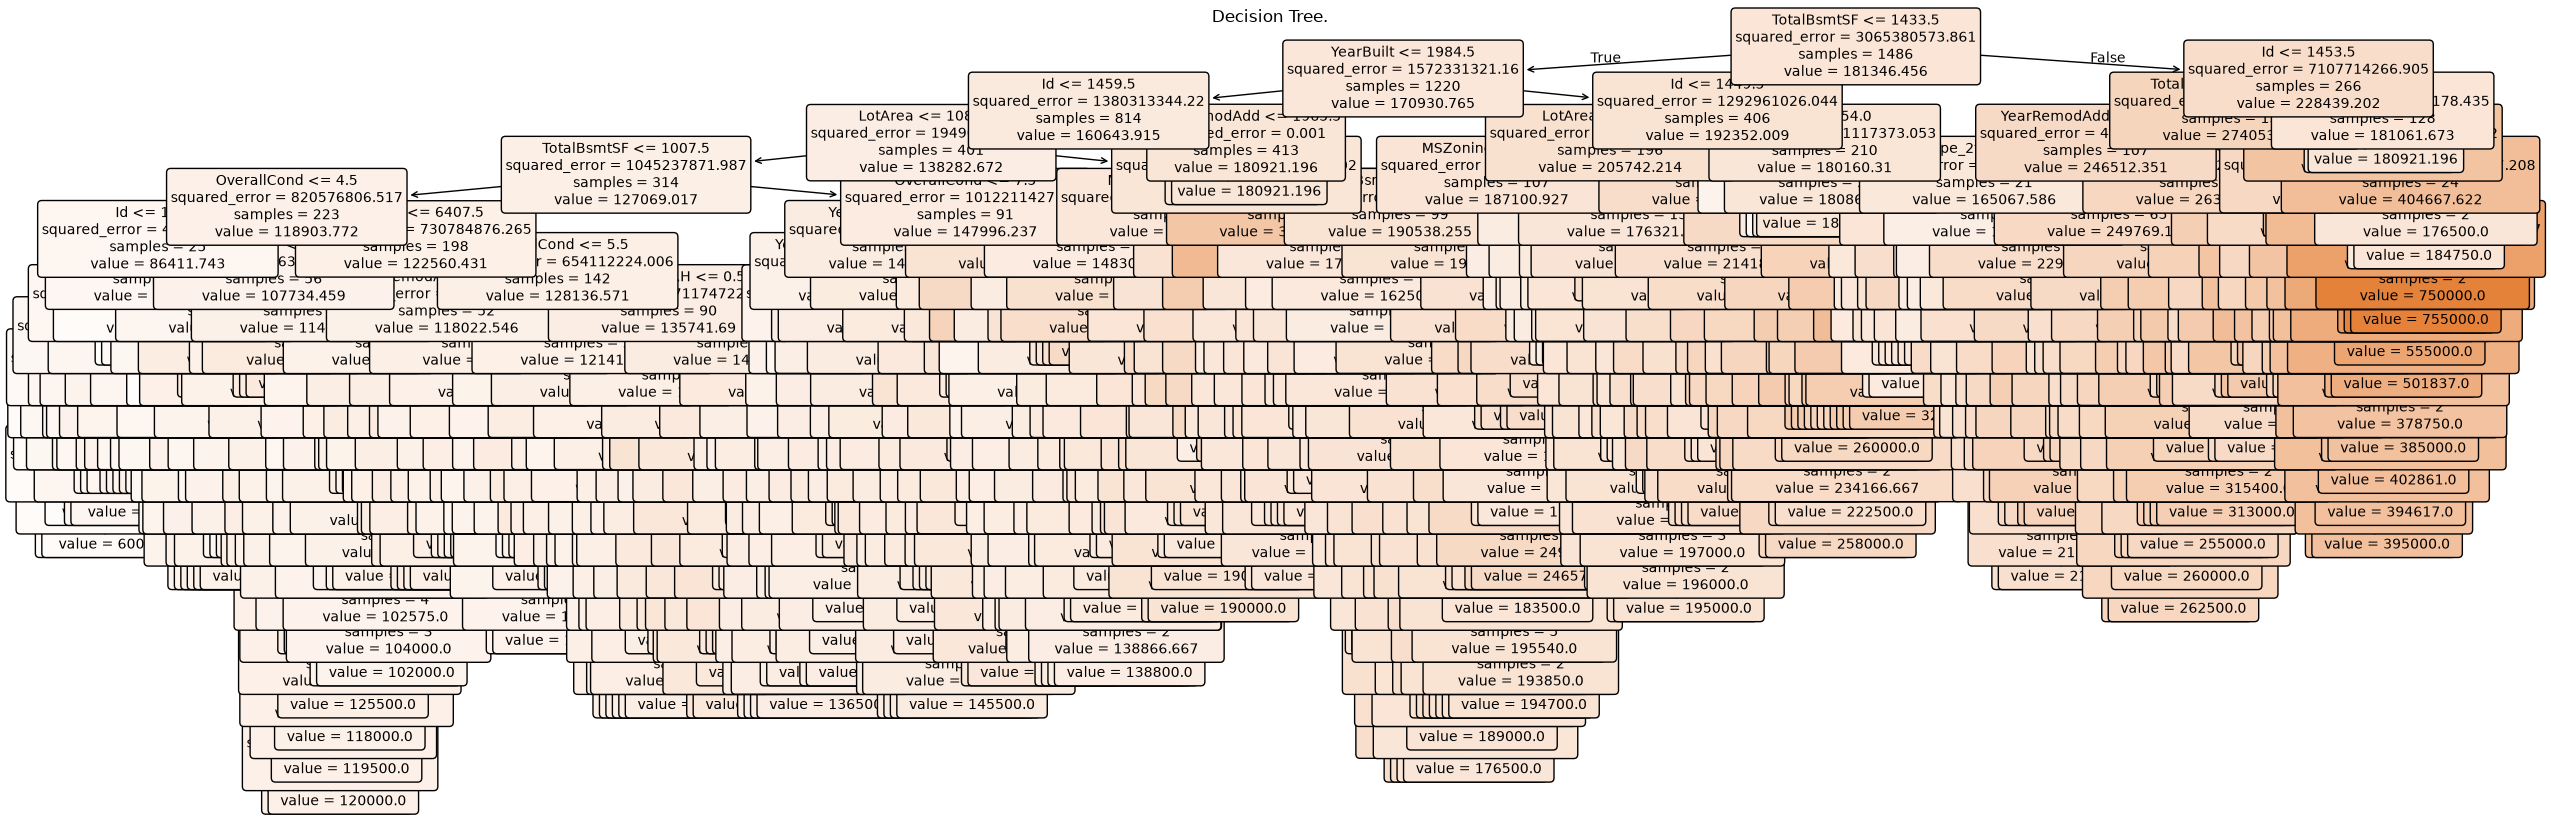

In [42]:
tree_to_plot = model_RFR.estimators_[0]

plt.figure(figsize=(30,10))
plot_tree(tree_to_plot, feature_names=hp_final.columns.tolist(), filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree.")
plt.show

In [41]:


model_LR = LinearRegression()
model_LR.fit(x_train, y_train)
Y_pred = model_LR.predict(x_valid)

print(mean_absolute_percentage_error(y_valid, Y_pred))

0.18633155158087458


Since Random Forest Regresor has the lowest absolute mean of error for this dataset, it will be the best fit.